                                                    NETFLIX PROJECT

In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("netflix_titles.csv")

In [3]:
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,25-Sep-21,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,24-Sep-21,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,24-Sep-21,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,24-Sep-21,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...
...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,20-Nov-19,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a..."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,1-Jul-19,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g..."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,1-Nov-19,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,11-Jan-20,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero..."


In [4]:
# df.shape

In [5]:
# 1 How has the number of Netflix titles added to the catalog changed over the years -

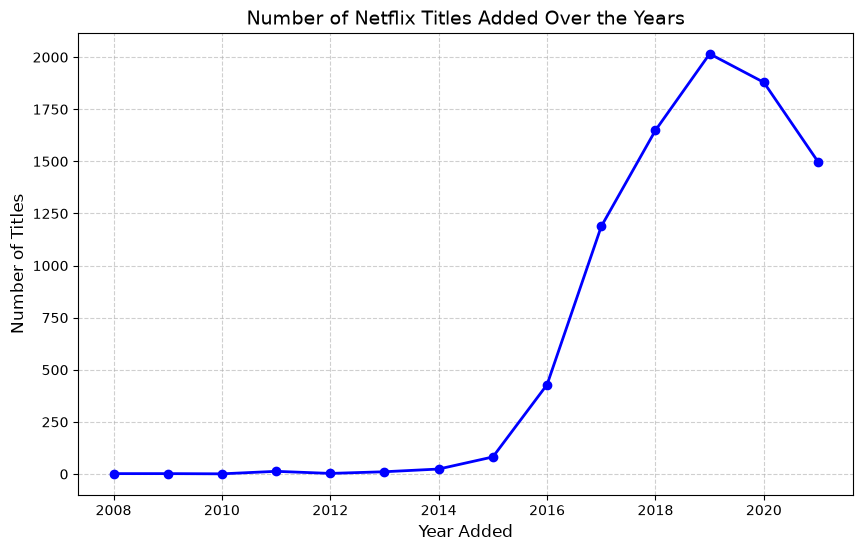

In [6]:
df = pd.read_csv("netflix_titles.csv")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), errors="coerce", format="mixed")
df["year_added"] = df["date_added"].dt.year

yearly_counts = df.groupby("year_added")["show_id"].count()


plt.figure(figsize=(10, 6))
yearly_counts.plot(kind="line", marker="o", color="b", linewidth=2)

plt.title("Number of Netflix Titles Added Over the Years", fontsize=14)
plt.xlabel("Year Added", fontsize=12)
plt.ylabel("Number of Titles", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)


In [7]:
# 2 What is the distribution of Movies Vs Tv shows on netflix -    

In [8]:
movies_tv_shows = df["type"].value_counts().reset_index()

In [9]:

movies_tv_shows

,type,count
0,Movie,6131
1,TV Show,2676


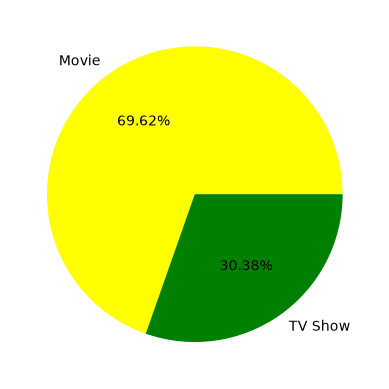

In [10]:
plt.pie(movies_tv_shows["count"], labels=movies_tv_shows["type"], autopct="%.2f%%", colors=["yellow",  "green"])

In [11]:
# 3 Which countries produce the most Netflix titles -

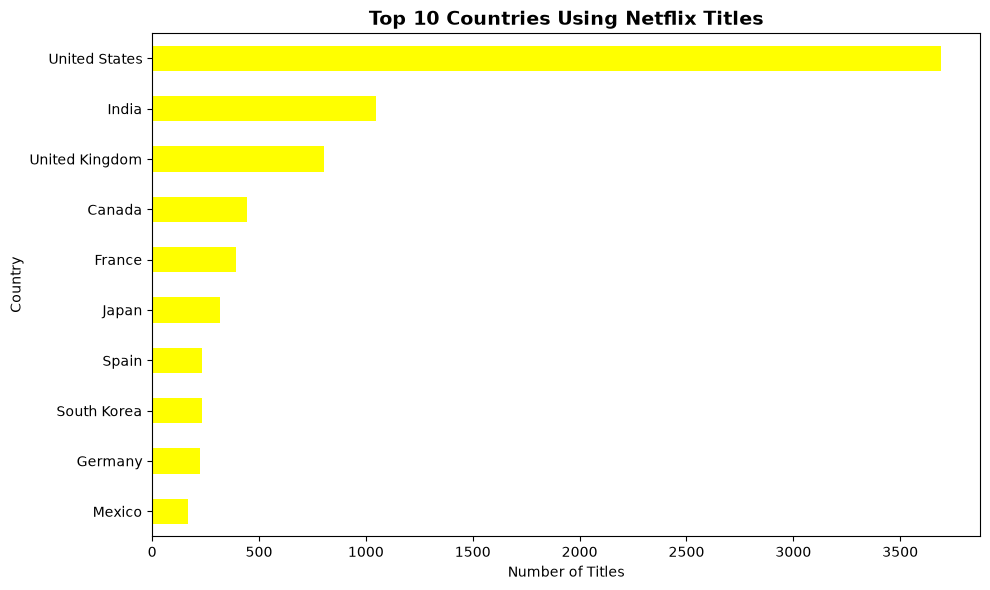

In [12]:
countries = df["country"].dropna().str.split(", ")
exploded_countries = countries.explode()
top_10 = exploded_countries.groupby(exploded_countries).size().nlargest(10)

plt.figure(figsize=(10, 6))
top_10.sort_values().plot(kind="barh", color="yellow")
plt.title("Top 10 Countries Using Netflix Titles", fontsize=14, fontweight="bold")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [13]:
# 4 Which genres/ countries have the most titles on netflix - 

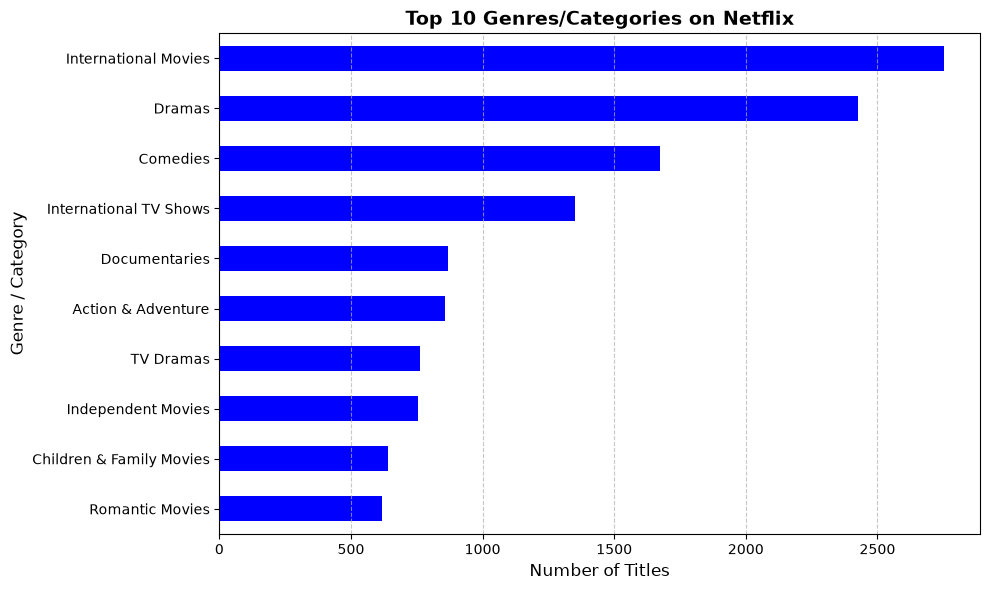

In [14]:

top_genres = (
    df["listed_in"]
    .str.split(",") 
    .explode()  
    .str.strip()
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))
top_genres.sort_values(ascending=True).plot(kind="barh", color="blue")

plt.title("Top 10 Genres/Categories on Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Number of Titles", fontsize=12)
plt.ylabel("Genre / Category", fontsize=12)
plt.grid(axis="x", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()

In [15]:
# 5  Which years had the highest number of titles released - 
df

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021.0
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021.0
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021.0
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021.0
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey J...",United States,2019-11-20,2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a...",2019.0
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,2019-07-01,2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young g...",2019.0
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, ...",United States,2019-11-01,2009,R,88 min,"Comedies, Horror Movies",Looking to survive in a world taken over by zo...,2019.0
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Ma...",United States,2020-01-11,2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero...",2020.0


    release_year  total_titles_released
70          2018                   1147
69          2017                   1032
71          2019                   1030
72          2020                    953
68          2016                    902
73          2021                    592
67          2015                    560
66          2014                    352
65          2013                    288
64          2012                    237


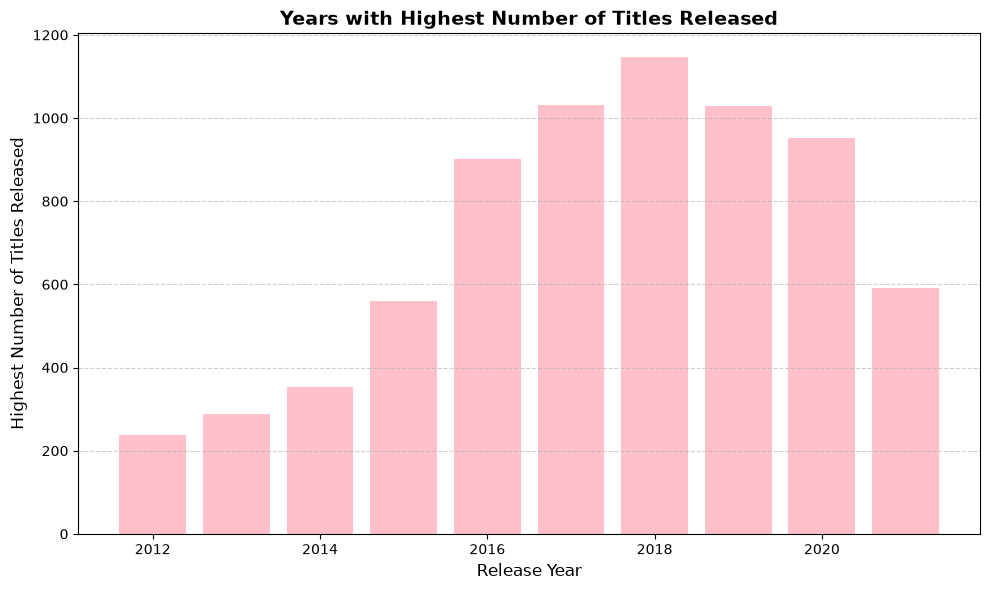

In [16]:
highest_release_years = (
    df.groupby("release_year")
    .agg(total_titles_released=("show_id", "count"))
    .reset_index()
    .sort_values(by="total_titles_released", ascending=False)
    .head(10)
)

print(highest_release_years)

plt.figure(figsize=(10, 6))
plt.bar(
     highest_release_years["release_year"],
     highest_release_years["total_titles_released"],
    color="pink"
)

plt.title(
    "Years with Highest Number of Titles Released", fontsize=14, fontweight="bold"
)
plt.xlabel("Release Year", fontsize=12)
plt.ylabel("Highest Number of Titles Released", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [17]:
 # 6 How has Netflix's Movie Vs TV Show composition changed over time - 

C:\Users\DELL\AppData\Local\Temp\ipykernel_976\3309763351.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_added"] = pd.to_datetime(df["date_added"].str.strip())


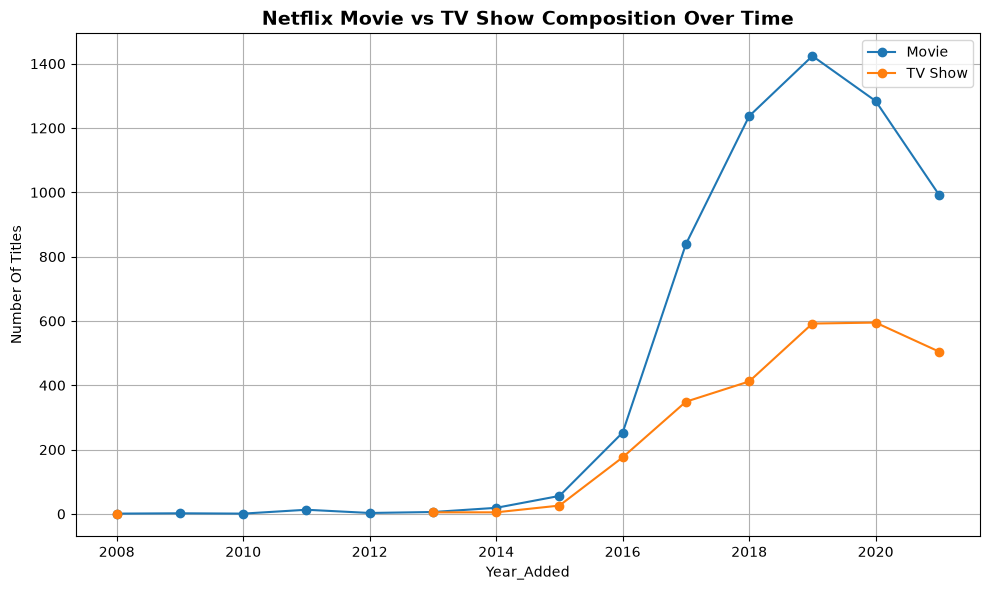

In [18]:
df = pd.read_csv("netflix_titles.csv")
df["date_added"] = pd.to_datetime(df["date_added"].str.strip())
df["year_added"] = df["date_added"].dt.year
composition = df.groupby(["year_added", "type"]).size().unstack()

plt.figure(figsize=(10,6))
plt.plot(composition.index, composition["Movie"], label="Movie", marker="o")
plt.plot(composition.index, composition["TV Show"], label="TV Show", marker="o")
plt.title("Netflix Movie vs TV Show Composition Over Time", fontsize="14", fontweight="bold")
plt.xlabel("Year_Added")
plt.ylabel("Number Of Titles")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
# 7 What are the most common content ratings on Netflix -


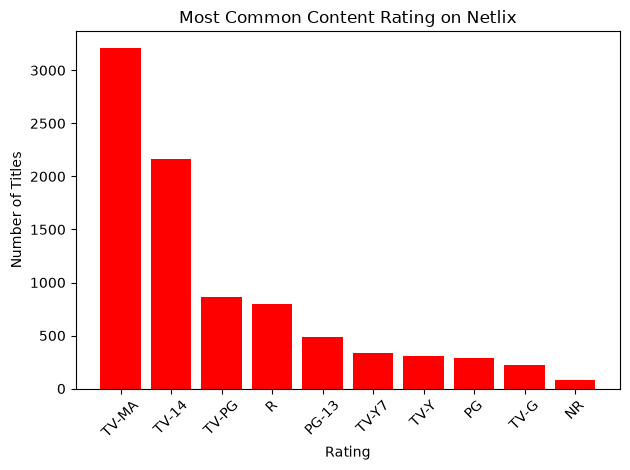

In [20]:

ratings = df["rating"].value_counts().head(10).reset_index()

plt.bar(ratings["rating"], ratings["count"], color="red")
plt.title("Most Common Content Rating on Netlix")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
# 8 How does movie duration vary across Netflix's catalog - 


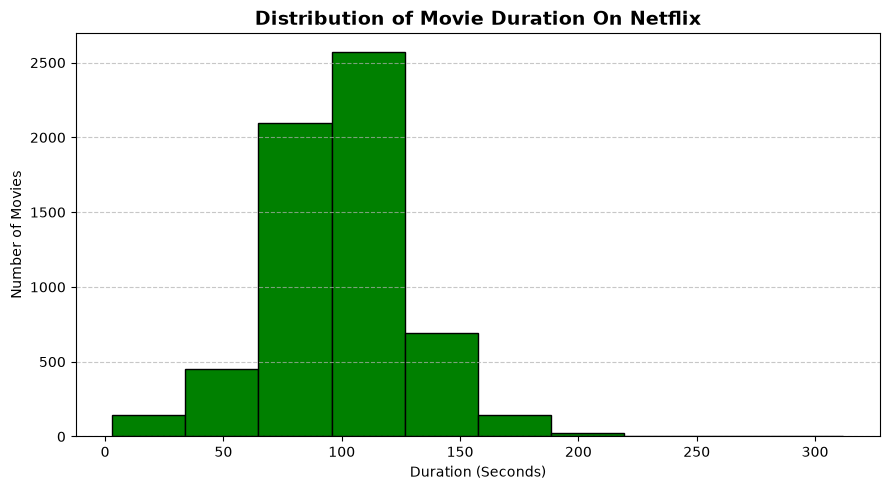

In [22]:
movies = df[df["type"] == "Movie"].copy()
movies["duration_num"] = movies.duration.str.split().str[0]
movies["duration_num"] = movies["duration_num"].astype("float", errors="ignore")
plt.figure(figsize=(9, 5))
plt.hist(movies["duration_num"].dropna(), bins=10, color="green", edgecolor="black")
plt.title("Distribution of Movie Duration On Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Duration (Seconds)")
plt.ylabel("Number of Movies")

plt.tight_layout()
plt.grid(axis="y", linestyle="--", alpha= 0.7)
plt.show()


In [23]:
import matplotlib.pyplot as plt
import pandas as pd 

In [24]:
# 9  What is the relationship between movie and release year - 

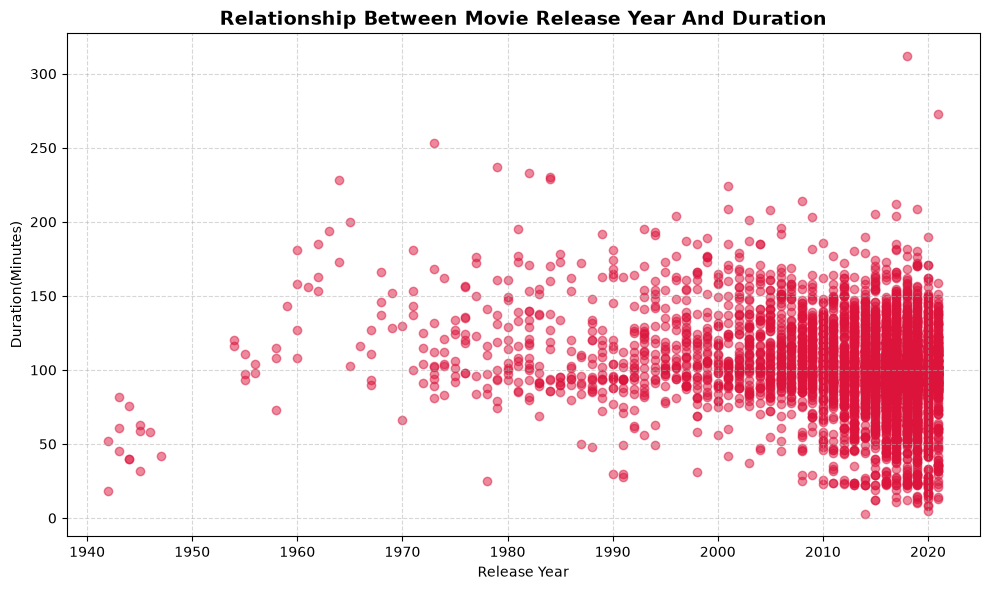

In [25]:
df = pd.read_csv("netflix_titles.csv")
movies = df[df["type"] == "Movie"].copy()
movies["duration_num"] = pd.to_numeric(movies["duration"].str.extract(r"(\d+)")[0])
movies_clean = movies.dropna(subset=["release_year", "duration_num"])

plt.figure(figsize=(10,6))
plt.scatter(movies_clean["release_year"], movies_clean["duration_num"], alpha=0.5, color="crimson")
plt.title("Relationship Between Movie Release Year And Duration", fontsize=14, fontweight="bold")
plt.xlabel("Release Year")
plt.ylabel("Duration(Minutes)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [26]:
# 10 Who are the directors with the most Netflix titles - 

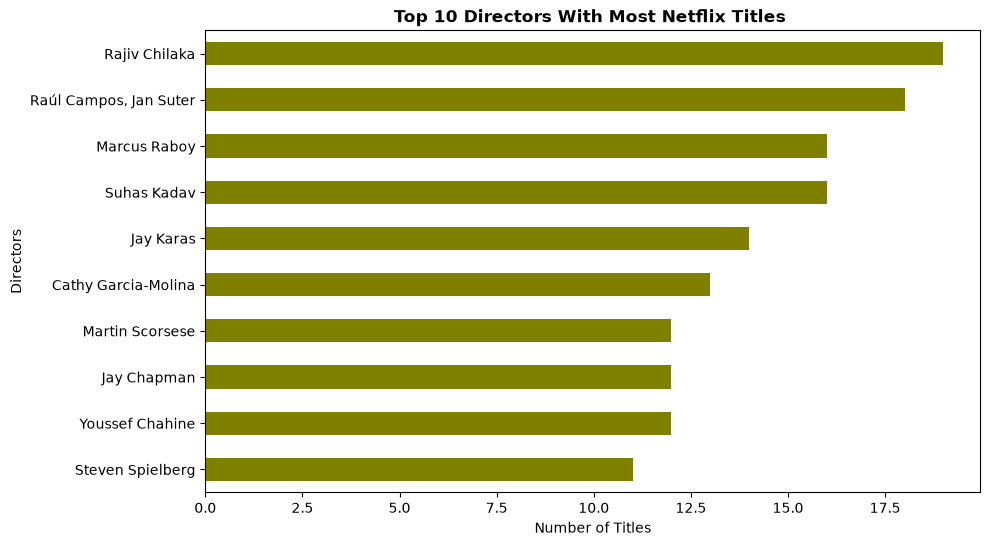

In [27]:
top_directors = df["director"].value_counts().head(10)

plt.figure(figsize=(10, 6))
top_directors.sort_values().plot(kind="barh", color="olive")

plt.title("Top 10 Directors With Most Netflix Titles ", fontweight="bold")
plt.xlabel("Number of Titles")
plt.ylabel("Directors")
plt.show()

In [28]:
# 11 Which actors appear most frequently across Netflix Titles - 

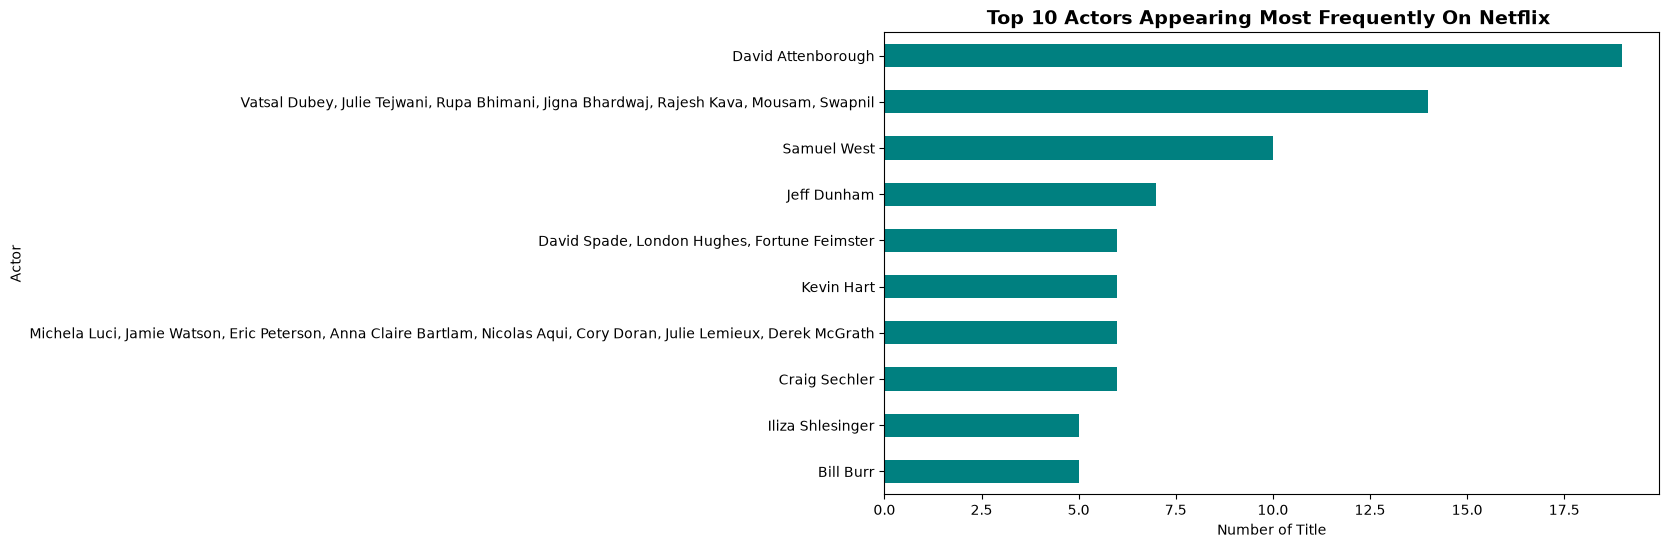

In [29]:
actors = df["cast"].dropna().str.strip(", ").explode()
top_actors = actors = actors.value_counts().head(10)

plt.figure(figsize=(10, 6))
top_actors.sort_values().plot(kind="barh", color="teal")

plt.title("Top 10 Actors Appearing Most Frequently On Netflix ", fontsize=14, fontweight="bold")
plt.xlabel("Number of Title")
plt.ylabel("Actor")
plt.show()

In [30]:
# 12 How long after release are title typicaaly added to Netflix- 

C:\Users\DELL\AppData\Local\Temp\ipykernel_976\4077186156.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["year_added"] = pd.to_datetime(df["date_added"].str.strip()).dt.year


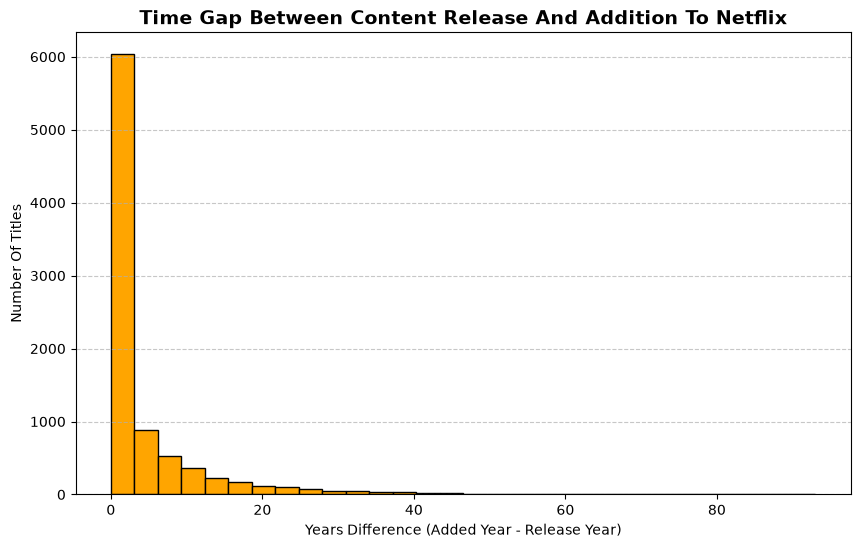

In [31]:
df["year_added"] = pd.to_datetime(df["date_added"].str.strip()).dt.year
df["years_to_add"] = df["year_added"] - df["release_year"]
clean_diff = df[df["years_to_add"] >= 0]["years_to_add"]

plt.figure(figsize=(10, 6))
plt.hist(clean_diff, bins=30, color="orange", edgecolor="black")
plt.title("Time Gap Between Content Release And Addition To Netflix", fontsize=14, fontweight="bold")
plt.xlabel("Years Difference (Added Year - Release Year)")
plt.ylabel("Number Of Titles")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()


In [32]:
# 13 Which months see the most Netflix titles added - 

C:\Users\DELL\AppData\Local\Temp\ipykernel_976\715389489.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["date_added"] = pd.to_datetime(df["date_added"].str.strip())


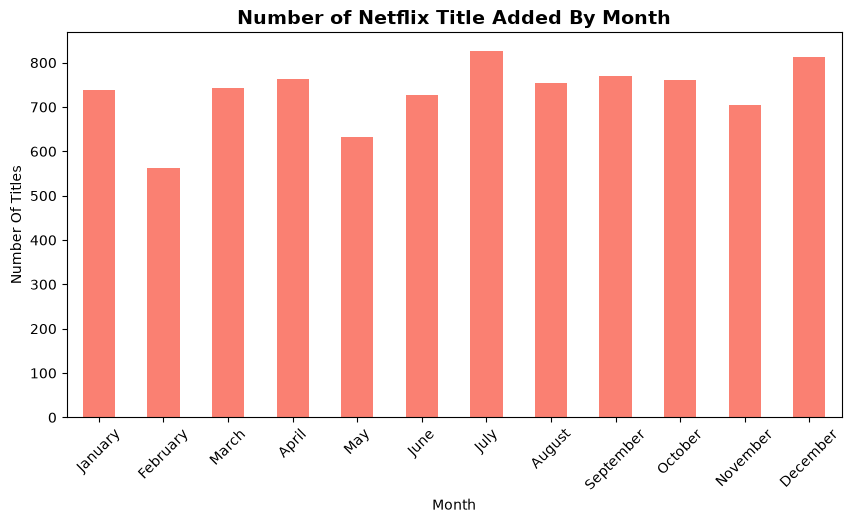

In [35]:
df["date_added"] = pd.to_datetime(df["date_added"].str.strip())
monthly_counts = df["date_added"].dt.month_name().value_counts()
months_order = ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
monthly_counts = monthly_counts.reindex(months_order)

plt.figure(figsize=(10, 5))
monthly_counts.plot(kind="bar", color="salmon")
plt.title("Number of Netflix Title Added By Month", fontsize=14, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number Of Titles")
plt.xticks(rotation=45)
plt.show()          

In [36]:
# 14 How does the distribution of ratings differ between Movies and TV Shows - 

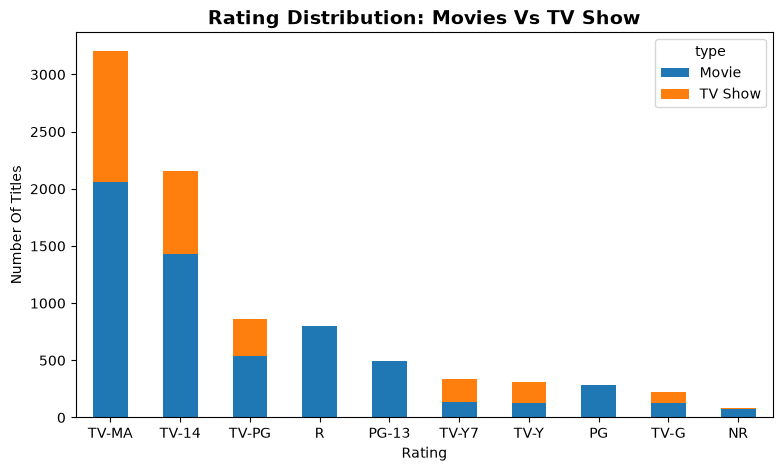

In [37]:
rating_counts = pd.crosstab(df["rating"], df["type"])
top_10_ratings = df["rating"].value_counts().head(10).index
rating_counts = rating_counts.loc[top_10_ratings]

rating_counts.plot(kind="bar", stacked=True, figsize=(9, 5))
plt.title("Rating Distribution: Movies Vs TV Show" , fontsize=14, fontweight="bold")
plt.xlabel("Rating")
plt.ylabel("Number Of Titles")
plt.xticks(rotation=0)
plt.show()
                            

In [38]:
# 15 Which genres are most associated with Movies VS TV Shows - 

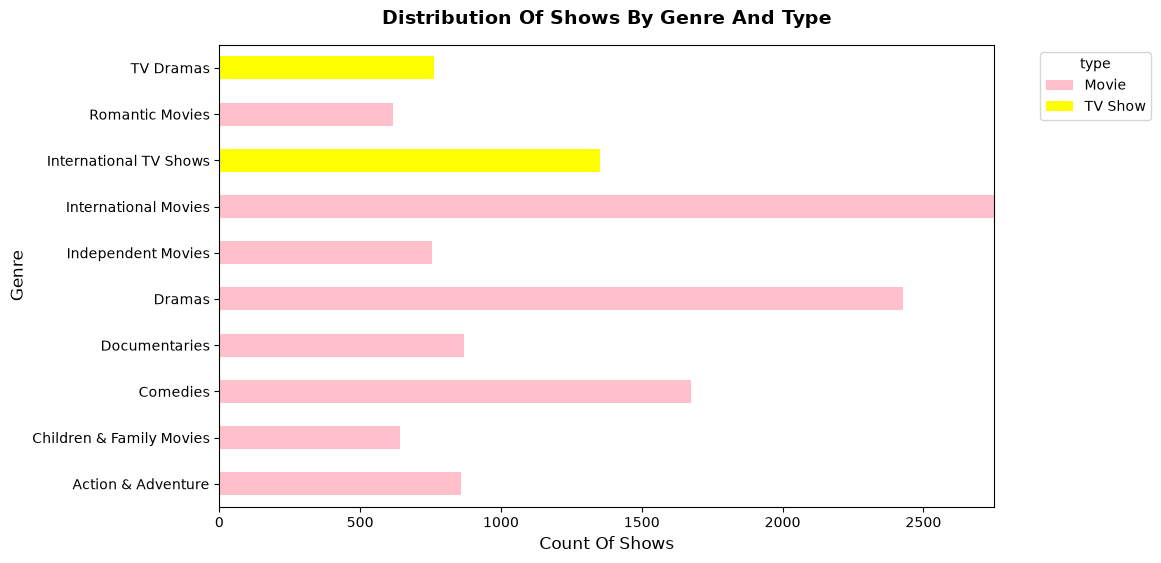

In [39]:
df_exploded = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre")
top_10_genres = df_exploded["genre"].value_counts().head(10).index
filtered_df = df_exploded[df_exploded["genre"].isin(top_10_genres)]
final = filtered_df.groupby(["genre", "type"])["show_id"].count().reset_index()
final

pivot_df = final.pivot(index="genre", columns="type", values="show_id")

ax = pivot_df.plot(kind="barh", stacked=True, figsize=(10, 6), color=["pink", "yellow"])

# clean up the formatting
plt.title("Distribution Of Shows By Genre And Type", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Count Of Shows", fontsize=12)
plt.ylabel("Genre", fontsize=12)
plt.legend(title="type", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.show()